# Point-to-point movement of the robot
Import of neccesary libraries.

In [1]:
import numpy as np                                  # library used for working with arrays
import matplotlib.pyplot as plt                     # library for creating visualizations
from scipy.integrate import solve_ivp               # numerical ODE solver
import math as m                                    # access to the mathematical functions defined by the C standard

Setting parameters and for the DC motors and differential drive robot kinematics.

In [2]:
T_m = 0.08                                          # electromechanical time constant
k_e = 0.5                                           # constructive constant of the motor
n = 40001                                           # number of simulation steps
t = np.linspace(0,400,n)                            # setting of time space in seconds
B = 0.15                                            # base distance between the wheels in meters
r = 0.026                                           # wheel radius in meters
way_points = 21                                     # number of the points on the generated trajectory
frame_value = 256                                   # number of frames in the animation of the robot trajectory

Ordinary differencial equation of the DC motor model without viscous friction. It's needed to set up releations between the real robot control, where you are using a Pulse Wide Modulation PWM in diapasone [-100%, 100%] from the maximum voltage of the battery.

In [3]:
def dc_motor(t, y, u):
    omega = y[1]                                    #taking a previous DC motor speed
    dtheta_dt = omega                               #equation for the DC motor speed
    domega_dt = u/(T_m * k_e) - omega/T_m           #equation for the DC motor acceleration
    return [dtheta_dt, domega_dt]                   #return [speed, acceleration]

Set up of environmental variables.

In [4]:
state_l = [0 , 0]                                   # state of the left motor
state_r = [0 , 0]                                   # state of the right motor
control_l = np.zeros(n)                             # control signal array for the left motor
control_r = np.zeros(n)                             # control signal array for the right motor
theta_l = np.zeros(n)                               # left motor rotation angle
theta_r = np.zeros(n)                               # right motor rotation angle
x = np.zeros(n)                                     # X coordinates
y = np.zeros(n)                                     # Y coordinates
path = np.zeros(n)                                  # calculated path
course = np.zeros(n)                                # course angle array
distance = np.zeros(n)                              # distance to the point
bearing = np.zeros(n)                               # robot bearing angle array
courseAngle = np.zeros(n)                           # массив курсовых углов
X_ref = -1                                          # X coordinate of the point
Y_ref = -1                                          # Y coordinate of the point
distance [0] = m.sqrt((X_ref)**2+(Y_ref)**2)        # distance to the point
bearing [0] = m.atan2(Y_ref,X_ref)                  # bearing angle
i = 1                                               # robot kinematic and dynamic counter
k = 1                                               # waypoints counter

Desired trajectory description. It's defined for the whole range of the robot trajectory movement and devided by number of waypoints where the robot will try to get.

In [5]:
def trajectory(way_points):                                                           # number of points on the trajectory
    theta = np.linspace(0, 4 * np.pi, way_points)                                     # generation of the trajectory space
    x_t = -1 + np.cos(theta) + 0.5 * theta                                            # moving spiral
    y_t = np.sin(theta)
    return x_t, y_t

Here is a modified version of the point-to-point movement algorithm with serial waypoints on the desired trajectory. Initially, the trajectory generation function is called and a global cycle with a *k* counter covers all waypoints. Inside the waypoints loop , the robot's kinematic and dynamic calculations use an *i* counter.

For the robot 's kinematic block, **path, course, x, y, distance, bearing, courseAngle** parameters are used. The next block is the control signal with **control_l , control_r** parameters. Finally, there is a block with the implementation of the control signal to the DC motor model on the **t_span = (t[i-1], t[i])** time frame. The *solve_ivp* function also requires the control signal value and a concrete time **t_eval = [t[i-1], t[i]]** where the ODE will be solved numerically.

0.12317625973392676 0.5877852522924731
-0.06266447490709393 0.9510565162951535
-0.3665391982980095 0.9510565162951536
-0.5523799329390302 0.5877852522924732
-0.42920367320510344 1.2246467991473532e-16
0.07593859777892842 -0.587785252292473
0.8900978631379077 -0.9510565162951535
1.8222911172467817 -0.9510565162951536
2.6364503826057613 -0.5877852522924734
3.141592653589793 -2.4492935982947064e-16
3.26476891332372 0.5877852522924729
3.078928178682699 0.9510565162951535
2.775053455291784 0.9510565162951536
2.589212720650763 0.5877852522924734
2.7123889803846897 3.6739403974420594e-16
3.2175312513687215 -0.5877852522924728
4.0316905167277 -0.9510565162951534
4.963883770836574 -0.9510565162951538
5.778043036195554 -0.5877852522924735
6.283185307179586 -4.898587196589413e-16


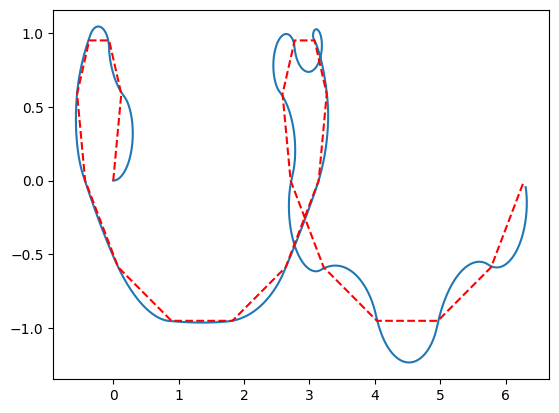

In [6]:
x_t, y_t = trajectory(way_points)                                                     # trajectory generation

for k in range(k,way_points):                                                         # loop for trajectory points
      X_ref = x_t[k]                                                                  # next goal X coordinate
      Y_ref = y_t[k]                                                                  # next goal Y coordinate
      distance [i-1] = 1                                                              # make distance non zero to enter new cycle

      while distance[i-1] > 0.05:                                                     # cycle for one trajectory point with the accuracy for the robot in meters
          if i+1 >= n:                                                                # if indexer overflow - break
            break

          path[i] = (theta_r[i-1] + theta_l[i-1]) * r / 2                             # calculation of the distance traveled
          course[i] = (theta_r[i-1] - theta_l[i-1]) * r / B                           # calculation of the robot's rotation angle
          x[i] = x[i-1] + (path[i]-path[i-1]) * m.cos(course[i])                      # X coordinate computation
          y[i] = y[i-1] + (path[i]-path[i-1]) * m.sin(course[i])                      # Y coordinate computation
          distance [i] = m.sqrt((X_ref - x[i])**2+(Y_ref - y[i])**2)                  # distance to the goal
          bearing [i] = m.atan2(Y_ref - y[i],X_ref - x[i])                            # bearing angle
          courseAngle [i] = bearing [i] - course [i]                                  # heading angle
          if courseAngle[i] > np.pi:
                  courseAngle[i] = courseAngle[i] - 2 * np.pi
          if courseAngle[i] < -np.pi:
                  courseAngle[i] = courseAngle[i] + 2 * np.pi                         # bringing the heading angle to the range [-pi, pi]

          #control_l [i] = 10 * np.cos (courseAngle [i]) * np.tanh(distance [i]) - 2 * (courseAngle [i]) # nonlinear control signal according Lyapunov function
          #control_r [i] = 10 * np.cos (courseAngle [i]) * np.tanh(distance [i]) + 2 * (courseAngle [i]) # nonlinear control signal according Lyapunov function
          control_l [i] = 8 * distance [i] - 1 * courseAngle [i]                      # proportional controller
          control_r [i] = 8 * distance [i] + 1 * courseAngle [i]                      # proportional controller
          if control_l[i] > 8:
                  control_l[i] = 8
          if control_l[i] < -8:
                  control_l[i] = -8
          if control_r[i] > 8:
                  control_r[i] = 8
          if control_r[i] < -8:
                  control_r[i] = -8                                                   # limitation of the control signal

          t_span = (t[i-1], t[i])
          t_eval = [t[i-1], t[i]]
          motor_l = solve_ivp(dc_motor, t_span, state_l, args=(control_l[i-1],), t_eval=t_eval)    # ODE solution for the left motor
          state_l = motor_l.y[:, -1]                                                               # getting a state of the left motor
          theta_l[i] = motor_l.y[0, -1]                                                            # left motor rotation
          motor_r = solve_ivp(dc_motor, t_span, state_r, args=(control_r[i-1],), t_eval=t_eval)    # ODE solution for the right motor
          state_r = motor_r.y[:, -1]                                                               # getting a state of the right motor
          theta_r[i] = motor_r.y[0, -1]                                                            # right motor rotation
          i = i + 1

      print(X_ref, Y_ref)                                                                          # display passed waypoints

x_model = x[:i]                                                                                    # save the trajectory without a tail of zeros
y_model = y[:i]
courseAngle_model = courseAngle[:i]

plt.plot(x_model, y_model)                                                                         # plot the robot trajectory and desired path
plt.plot(x_t, y_t, 'r--')

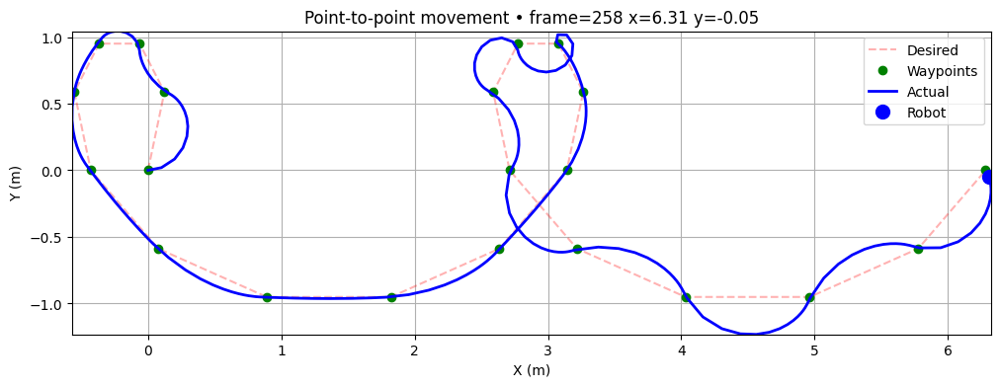

In [20]:
import matplotlib.animation as animation                                        # import animation library
from IPython.display import HTML                                                # HTML module
matplotlib.rcParams['animation.embed_limit'] = 2**128                           # incrise the size of the animation

skip = i // frame_value                                                         # calculation of the value frames to skip
x_down = x_model[::skip]                                                        # downgrading the framerate for memory and space issues
y_down = y_model[::skip]
courseAngle_model = courseAngle_model[::skip]

fig, ax = plt.subplots(figsize=(12, 6))                                         # create a space for the animation

ax.plot(x_t, y_t, 'r--', alpha=0.3, label='Desired')                            # disered trajectory
ax.plot(x_t, y_t, 'go', markersize=6, label='Waypoints')                        # draw waypoints

actual_line, = ax.plot([],[], 'b-', linewidth=2, label='Actual')                # defenition of the trajectory line
robot_dot,  = ax.plot([],[], 'o', markersize=10, color='blue', label='Robot')   # defenition of the robot body

ax.set_xlim(min(min(x_down), min(x_t)), max(max(x_down), max(x_t)))             # limitation of the X and Y coordinates
ax.set_ylim(min(min(y_down), min(y_t)), max(max(y_down), max(y_t)))
ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)')                                  # labels
ax.set_aspect('equal'); ax.grid(True); ax.legend()                              # legend

def update(frame):                                                              # definition of the single frame
    actual_line.set_data([x_down[:frame+1], y_down[:frame+1]])
    robot_dot.set_data([x_down[frame]], [y_down[frame]])
    ax.set_title(f'Point-to-point movement • frame={frame} x={x_down[frame]:.2f} y={y_down[frame]:.2f}')
    return actual_line, robot_dot

anim = animation.FuncAnimation(fig, update, frames=len(x_down), interval=100, blit=True) # animation call

anim.save('trajectory.mp4', writer=animation.FFMpegWriter(fps=10))              # save the animation
HTML(anim.to_jshtml())                                                          # draw interactive animation